# Práctica 4. Primeros circuitos cuánticos con Qiskit

**Duración estimada:** 60–75 minutos   
**Herramientas:** Python, NumPy, Qiskit, Qiskit Aer y Matplotlib

> Completa las celdas marcadas con `TODO` y responde razonadamente en las celdas Markdown. Ejecuta al terminar **Kernel → Restart & Run All**.

## Objetivos

- Crear y visualizar circuitos de uno y dos qubits.
- Diferenciar qubits, bits clásicos, puertas y medidas.
- Preparar $|0\rangle$ y $|1\rangle$.
- Obtener amplitudes y probabilidades exactas con `Statevector`.
- Transpilar y ejecutar circuitos con `AerSimulator`.
- Obtener conteos, frecuencias e histogramas.
- Distinguir simulación exacta y muestreo.
- Interpretar el orden de bits de Qiskit.
- Comparar Qiskit con el formalismo matricial de NumPy.

## Entrega

Entrega este notebook con el nombre:

```text
04_primeros_circuitos_qiskit_apellidos_nombre.ipynb
```

Debe contener código ejecutado, circuitos dibujados, resultados, respuestas, pruebas y una conclusión final. No se aceptarán respuestas compuestas únicamente por código.

# Preparación del entorno

## Ejercicio 1. Instalación y comprobación

Si el entorno no dispone de las bibliotecas, descomenta y ejecuta la siguiente celda una sola vez. Reinicia después el kernel.

In [33]:
# Descomenta únicamente si necesitas instalar las dependencias.
# %pip install qiskit qiskit-aer matplotlib pylatexenc

In [34]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

np.set_printoptions(precision=5, suppress=True)

# TODO: muestra las versiones de Qiskit, Qiskit Aer y NumPy

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("NumPy:", np.__version__)

Qiskit: 2.5.2
Qiskit Aer: 0.17.2
NumPy: 2.4.6


### Responde

1. ¿Qué funciones aporta Qiskit?
2. ¿Para qué se utiliza Qiskit Aer?
3. ¿Por qué puede ser necesario reiniciar el kernel después de instalar?
4. ¿Qué biblioteca permite comparar los circuitos con matrices?

**Respuesta:**

1. Qiskit permite crear, manipular, simular y ejecutar circuitos cuánticos.
2. Qiskit Aer se utiliza para simular circuitos cuánticos en un ordenador clásico.
3. Porque el kernel puede necesitar cargar las bibliotecas recién instaladas.
4. NumPy permite trabajar con matrices y vectores para comparar los resultados.

# Parte A. Construcción de circuitos

## Ejercicio 2. Circuito vacío de un qubit

Crea un circuito con un qubit, sin bits clásicos ni puertas. Muestra el circuito, el número de qubits y el número de bits clásicos. Visualízalo en texto y con Matplotlib.

   
q: 
   
Número de qubits: 1
Numero de bits clásicos 0


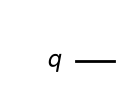

In [35]:
circuito_0 = QuantumCircuit(1) # Circuito con un qubit

# TODO: muestra el objeto y sus propiedades
# TODO: visualiza con draw() y draw("mpl")
print(circuito_0)
print("Número de qubits:", circuito_0.num_qubits)
print("Numero de bits clásicos", circuito_0.num_clbits)
display(circuito_0.draw(output="mpl"))

### Responde

1. ¿Qué estado tiene inicialmente el qubit?
2. ¿Un circuito vacío carece de estado?
3. ¿Se ha ejecutado al construirlo?
4. ¿Qué diferencia existe entre construir y ejecutar?
5. ¿Qué representa la línea horizontal?

**Respuesta:** 
1. Inicialmente el qubit está en el estado |0>.
2. No, aunque esté vacío, tiene un estado inicial.
3. No, construir un circuito no significa ejecutarlo.
4. Construir consiste en definir operaciones; ejecutar consiste en procesarlas para obtener resultados.
5. La línea horizontal representa el qubit y la secuencia de operaciones que se le aplican.

## Ejercicio 3. Circuito con un bit clásico
Crea un circuito con un qubit y un bit clásico, pero sin medidas. Consulta sus propiedades y visualízalo.

     
  q: 
     
c: 1/
     
Qubits: 1
Bits clásicos 1
     
  q: 
     
c: 1/
     


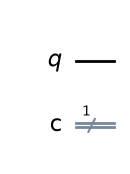

In [36]:
circuito_clasico = QuantumCircuit(1,1)

print(circuito_clasico)
print("Qubits:", circuito_clasico.num_qubits)
print("Bits clásicos", circuito_clasico.num_clbits)
print(circuito_clasico)
display(circuito_clasico.draw(output="mpl"))
# TODO: muestra num_qubits, num_clbits y el circuito

### Responde

1. ¿Qué diferencia presenta respecto al circuito anterior?
2. ¿Declarar un bit clásico mide automáticamente?
3. ¿Para qué se utilizará el bit clásico?
4. ¿Puede encontrarse en superposición?

**Respuesta:** 
1. Tiene un qubit y un bit clásico, mientras que el anterior solo tenía un qubit.
2. No, declarar un bit clásico no realiza una medida.
3. Se utiliza para almacenar el resultado de medir el qubit.
4. No, un bit clásico solo puede almacenar 0 o 1.

## Ejercicio 4. Preparación de $|1\rangle$

Crea un circuito de un qubit, aplica $X$ al qubit 0 y visualízalo.

   ┌───┐
q: ┤ X ├
   └───┘


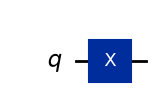

In [37]:
circuito_1 = QuantumCircuit(1)

# TODO: aplica X al qubit 0
# TODO: visualiza el circuito

circuito_1.x(0)
print(circuito_1)
display(circuito_1.draw(output="mpl"))

### Responde

1. ¿Cuál es el estado inicial?
2. ¿Qué transformación realiza $X$?
3. ¿Qué estado debe obtenerse?
4. ¿Qué indica el argumento de `x(0)`?
5. ¿Qué ocurriría al utilizar `x(1)` en este circuito?

**Respuesta:**
1. El estado inicial es |0>.
2. La puerta X intercambia los estados |0> y |1>.
3. Se obtiene |1>.
4. El argumento 0 indica que la puerta se aplica al qubit de índice 0.
5. x(1) produciría un error porque el circuito solo tiene un qubit.

## Ejercicio 5. Dos aplicaciones de $X$
Construye y visualiza un circuito con dos puertas $X$ consecutivas sobre el mismo qubit. Predice el estado final antes de simularlo.

   ┌───┐┌───┐
q: ┤ X ├┤ X ├
   └───┘└───┘


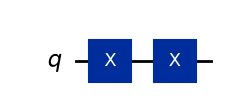

In [38]:
circuito_xx = QuantumCircuit(1)

# TODO: aplica X dos veces y visualiza

circuito_xx.x(0)
circuito_xx.x(0)

print(circuito_xx)
display(circuito_xx.draw(output="mpl"))

### Responde

1. ¿Cuál debe ser el estado final?
2. ¿Qué relación se cumple entre $X^2$ y la identidad?
3. ¿Importa que ambas puertas actúen sobre el mismo qubit?
4. ¿Se aplican simultáneamente?

**Respuesta:** 

1. El estado final es |0>.
2. X^2=I, es decir, aplicar dos veces X equivale a la identidad.
3. Sí, deben actuar sobre el mismo qubit para cancelar sus efectos de esa manera.
4. No, se aplican consecutivamente.

# Parte B. Vectores de estado

## Ejercicio 6. Estado del circuito vacío

Obtén `Statevector.from_instruction(circuito_0)`. Muestra el objeto, `data`, sus tipos y la forma del array. Compáralo con $|0\rangle=(1,0)^T$.

In [39]:
estado_0 = Statevector.from_instruction(circuito_0)

ket_0_numpy = np.array([1, 0], dtype=complex)

print("Statevector:", estado_0)
print("data:", estado_0.data)
print("Tipo del objeto:", type(estado_0))
print("Tipo de data:", type(estado_0.data))
print("dtype:", estado_0.data.dtype)
print("shape:", estado_0.data.shape)
print("Coincide con |0>:", np.allclose(estado_0.data, ket_0_numpy))

# TODO: muestra la información y compara con np.allclose()

Statevector: Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
data: [1.+0.j 0.+0.j]
Tipo del objeto: <class 'qiskit.quantum_info.states.statevector.Statevector'>
Tipo de data: <class 'numpy.ndarray'>
dtype: complex128
shape: (2,)
Coincide con |0>: True


### Responde

1. ¿Qué diferencia existe entre `Statevector` y `data`?
2. ¿Cuántas amplitudes contiene un qubit?
3. ¿Por qué son complejas?
4. ¿Por qué se utiliza `np.allclose()`?

**Respuesta:**
1. Statevector es un objeto que representa el estado cuántico; .data contiene el array de sus amplitudes.
2. Un qubit tiene dos amplitudes.
3. Porque las amplitudes cuánticas pueden tener fase y se representan mediante números complejos.
4. np.allclose() permite comparar números con pequeñas diferencias de precisión numérica

## Ejercicio 7. Estado después de $X$
Obtén el vector de `circuito_1`. Muestra norma, amplitudes y probabilidades. Compáralo con $|1\rangle=(0,1)^T$.

In [40]:
circuito_1 = QuantumCircuit(1)
circuito_1.x(0)
estado_1 = Statevector.from_instruction(circuito_1)
ket_1_numpy = np.array([0, 1], dtype=complex)

print("Statevector:", estado_1)
print("data:", estado_1.data)
print("Tipo del objeto:", type(estado_1))
print("Tipo de data:", type(estado_1.data))
print("dtype:", estado_1.data.dtype)
print("shape:", estado_1.data.shape)
print("Coincide con |1>:", np.allclose(estado_1.data, ket_1_numpy))

# TODO: muestra vector, norma, amplitudes y probabilidades
# TODO: compara con ket_1_numpy

Statevector: Statevector([0.+0.j, 1.+0.j],
            dims=(2,))
data: [0.+0.j 1.+0.j]
Tipo del objeto: <class 'qiskit.quantum_info.states.statevector.Statevector'>
Tipo de data: <class 'numpy.ndarray'>
dtype: complex128
shape: (2,)
Coincide con |1>: True


### Responde

1. ¿Qué amplitud tiene cada estado de la base?
2. ¿Qué probabilidad tiene cada resultado?
3. ¿Se necesitan shots para obtener este vector?
4. ¿Se ha realizado una medida?

**Respuesta:**
1. La amplitud de |0> es 0 y la de |1> es 1.
2. P(0)=0 y P(1)=1.
3. No, el vector se obtiene directamente de forma exacta mediante simulación.
4. No, solamente se ha calculado el estado.

## Ejercicio 8. Estado después de dos $X$
Obtén el estado exacto de `circuito_xx` y comprueba que coincide con $|0\rangle$.

In [41]:
estado_xx = Statevector.from_instruction(circuito_xx)

print("Estado final:", estado_xx.data)
print("Coincide con |0>:", np.allclose(
    estado_xx.data,
    ket_0_numpy
))

Estado final: [1.+0.j 0.+0.j]
Coincide con |0>: True


### Responde

1. ¿Ha cambiado el circuito aunque coincida el estado final?
2. ¿Es igual un circuito vacío a otro con dos puertas $X$?
3. ¿Puede deducirse toda la secuencia observando solo el estado final?

**Respuesta:**
1. Sí, el circuito contiene operaciones aunque el estado final coincida con el inicial.
2. No, son circuitos diferentes, aunque sus estados finales sean iguales.
3. No, el estado final no permite reconstruir necesariamente todas las operaciones aplicadas

## Ejercicio 9. Probabilidades exactas

Para los tres estados anteriores, muestra `probabilities()` y `probabilities_dict()` y construye una tabla comparativa.

In [42]:
estado_0 = QuantumCircuit(1)
estado_1= QuantumCircuit(1)
estado_1.x(0)
estado_xx = QuantumCircuit(1)
estado_xx.x(0)
estado_xx.x(0)


estados_exactos = {
    "Vacío": estado_0,
    "Una X": estado_1,
    "Dos X": estado_xx,
}

# TODO: muestra vector y probabilidades para cada estado

for name,circuito in estados_exactos.items():
    print(circuito)
    estado = Statevector.from_instruction(circuito)
    pr = estado.probabilities_dict()
    
    print(f"P(0)={pr.get('0', 0)}, P(1)={pr.get('1', 0)}")

   
q: 
   
P(0)=1.0, P(1)=0
   ┌───┐
q: ┤ X ├
   └───┘
P(0)=0, P(1)=1.0
   ┌───┐┌───┐
q: ┤ X ├┤ X ├
   └───┘└───┘
P(0)=1.0, P(1)=0


### Responde

1. ¿Por qué el diccionario puede omitir resultados de probabilidad cero?
2. ¿Son probabilidades exactas o experimentales?
3. ¿Contienen toda la información del estado?
4. ¿Puede reconstruirse la fase solo con ellas?

**Respuesta:** 
1. Porque los estados con probabilidad cero pueden omitirse para simplificar el diccionario.
2. Son probabilidades teóricas calculadas a partir del estado.
3. No, no contienen toda la información del vector de estado.
4. No, las probabilidades no permiten recuperar las fases de las amplitudes

# Parte C. Comparación con NumPy

## Ejercicio 10. Puerta $X$ matricial

Representa $X$, calcula $X|0\rangle$, $X|1\rangle$ y $X^2|0\rangle$, y compara cada resultado con Qiskit.

In [43]:
X_numpy = np.array([
    [0, 1],
    [1, 0]
], dtype=complex)

resultado_x_0 = X_numpy @ ket_0_numpy
resultado_x_1 = X_numpy @ ket_1_numpy
resultado_xx_0 = X_numpy @ X_numpy @ ket_0_numpy

print("X|0> =", resultado_x_0)
print("X|1> =", resultado_x_1)
print("XX|0> =", resultado_xx_0)

print("Coincide X|0>:", np.allclose(
    resultado_x_0,
    Statevector.from_instruction(circuito_1).data
))

print("Coincide X|1>:", np.allclose(
    resultado_x_1,
    ket_0_numpy
))

print("Coincide XX|0>:", np.allclose(
    resultado_xx_0,
    Statevector.from_instruction(circuito_xx).data
))

X|0> = [0.+0.j 1.+0.j]
X|1> = [1.+0.j 0.+0.j]
XX|0> = [1.+0.j 0.+0.j]
Coincide X|0>: True
Coincide X|1>: True
Coincide XX|0>: True


### Responde

1. ¿Representan NumPy y Qiskit modelos físicos diferentes?
2. ¿Qué elemento de NumPy equivale a una puerta?
3. ¿Qué ventaja proporciona el modelo de circuitos?
4. ¿Por qué sigue siendo útil el formalismo matricial?

**Respuesta:**
1. No, ambos representan el mismo modelo de computación cuántica.
2. Una matriz unitaria equivale a una puerta cuántica.
3. Los circuitos permiten visualizar y organizar fácilmente las operaciones.
4. Porque las matrices permiten comprender matemáticamente las transformaciones

# Parte D. Medida

## Ejercicio 11. Medida de $|0\rangle$

Crea un circuito con un qubit y un bit clásico. Mide el qubit 0 en el bit clásico 0 y visualízalo.

     ┌─┐
  q: ┤M├
     └╥┘
c: 1/═╩═
      0 


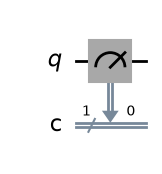

In [44]:
circuito_medida_0 = QuantumCircuit(1, 1)
circuito_medida_0.measure(0,0) #qubit que se mide y bit clásico donde se guarda el resultado
# TODO: añade la medida y visualiza
print(circuito_medida_0)
display(circuito_medida_0.draw(output="mpl"))

### Responde

1. ¿Qué significa la flecha de medida?
2. ¿Dónde se almacena el resultado?
3. ¿Cuál debe ser el resultado?
4. ¿La medida es una puerta unitaria?

**Respuesta:** 

1. La flecha indica que el resultado de la medida se envía a un bit clásico.
2. Se almacena en el bit clásico de índice 0.
3. El resultado es 0.
4. No, la medida no es una operación unitaria

## Ejercicio 12. Medida de $|1\rangle$
Construye $|0\rangle\xrightarrow{X}|1\rangle\xrightarrow{medida}1$ y visualízalo.

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


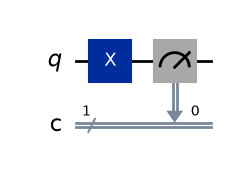

In [45]:
circuito_medida_1 = QuantumCircuit(1, 1)
circuito_medida_1.x(0)
circuito_medida_1.measure(0,0)
print(circuito_medida_1)
display(circuito_medida_1.draw(output="mpl"))
# TODO: aplica X, mide y visualiza



### Responde

1. ¿Qué operación se aplica primero?
2. ¿Cómo se identifica el orden temporal?
3. ¿Qué ocurriría si la medida apareciese antes de $X$?
4. ¿El resultado clásico sería el mismo?

**Respuesta:**
1. Primero se aplica X y después se mide.
2. Las operaciones se leen de izquierda a derecha en el circuito.
3. Se mediría primero el estado |0>, obteniendo 0, y después se aplicaría X al qubit.
4. No, el bit clásico almacenaría 0 en vez de 1

## Ejercicio 13. `measure_all()`

Crea dos qubits sin bits clásicos, aplica `measure_all()`, visualiza y consulta `num_clbits`.

        ┌───┐ ░ ┌─┐   
   q_0: ┤ X ├─░─┤M├───
        ├───┤ ░ └╥┘┌─┐
   q_1: ┤ Y ├─░──╫─┤M├
        └───┘ ░  ║ └╥┘
meas: 2/═════════╩══╩═
                 0  1 


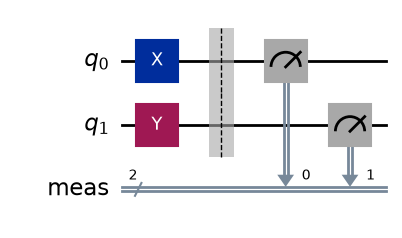

El nnumero de bits clasicos: 2


In [46]:
circuito_todos = QuantumCircuit(2)
circuito_todos.x(0)
circuito_todos.y(1)
circuito_todos.measure_all()
print(circuito_todos)
display(circuito_todos.draw(output="mpl"))
print("El nnumero de bits clasicos:",circuito_todos.num_clbits)

# TODO: mide todos los qubits, visualiza y muestra num_clbits

### Responde

1. ¿Qué ha añadido `measure_all()`?
2. ¿Cuántos bits clásicos aparecen?
3. ¿Qué diferencia presenta respecto a `measure(0, 0)`?
4. ¿Cuándo conviene controlar explícitamente la correspondencia?

**Respuesta:** 

1. Ha añadido medidas para todos los qubits y los bits clásicos necesarios.
2. Aparecen dos bits clásicos.
3. measure_all() mide automáticamente todos los qubits, mientras que measure(0,0) mide uno específico.
4. Cuando es importante controlar en qué bit clásico se guarda cada resultado

# Parte E. Ejecución con Aer

## Ejercicio 14. Simulador y transpilación

Crea `AerSimulator()`. Transpila los circuitos de medida de $|0\rangle$ y $|1\rangle$ para ese backend y visualiza los resultados.

AerSimulator('aer_simulator')


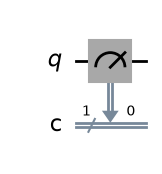

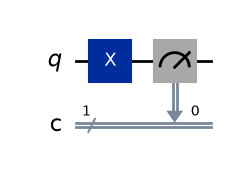

In [47]:
simulador = AerSimulator()

circuito_0_transpilado = transpile(circuito_medida_0, simulador)
circuito_1_transpilado = transpile(circuito_medida_1, simulador)

print(simulador)
display(circuito_0_transpilado.draw(output="mpl"))
display(circuito_1_transpilado.draw(output="mpl"))

# TODO: muestra el simulador y los circuitos transpilados

### Responde

1. ¿El simulador es el circuito?
2. ¿Por qué se adapta un circuito al backend?
3. ¿Qué finalidad tendrá la transpilación en hardware real?
4. ¿Un simulador ideal incorpora automáticamente ruido?

**Respuesta:** 
1. No, el simulador es el entorno que ejecuta el circuito.
2. Para adaptar las instrucciones a las operaciones admitidas por el backend.
3. Adaptar y optimizar el circuito para las características del hardware real.
4. No, un simulador ideal no incorpora ruido automáticamente.

## Ejercicio 15. Ejecución de $|0\rangle$
Ejecuta 1.000 shots con `seed_simulator=42`. Recupera el trabajo, el resultado y los conteos. Comprueba la suma.

In [48]:
circuito = QuantumCircuit(1,1)
#circuito.x(0)
estado = Statevector.from_instruction(circuito)
print(estado.data)
print(estado.probabilities())
prob = estado.probabilities_dict()
print(f"P(0)={prob.get('0', 0)}, P(1)={prob.get('1', 0)}")

circuito_0 = circuito.copy()
circuito_0.measure(0,0)

simulador = AerSimulator()
circuito_0_transpilado = transpile(circuito_0, simulador)


trabajo_0 = simulador.run(circuito_0_transpilado, shots= 1000, seed_simulator= 42)
print(trabajo_0)
resultado_0 = trabajo_0.result()
print(resultado_0)
if resultado_0.success :
    conteos_0 = resultado_0.get_counts()
    print(conteos_0.get('0', 0))

# TODO: muestra los objetos y comprueba el total

[1.+0.j 0.+0.j]
[1. 0.]
P(0)=1.0, P(1)=0


Result(backend_name='aer_simulator', backend_version='0.17.2', job_id='fbae6c12-c9ff-4280-b33e-20b63b0f353b', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x0': 1000}), header={'creg_sizes': [['c', 1]], 'global_phase': 0.0, 'memory_slots': 1, 'n_qubits': 1, 'name': 'circuit-155', 'qreg_sizes': [['q', 1]], 'metadata': {}}, status=DONE, seed_simulator=42, metadata={'batched_shots_optimization': False, 'required_memory_mb': 0, 'method': 'stabilizer', 'active_input_qubits': [0], 'device': 'CPU', 'remapped_qubits': False, 'num_qubits': 1, 'num_clbits': 1, 'time_taken': 0.005318, 'sample_measure_time': 0.0015766, 'input_qubit_map': [[0, 0]], 'max_memory_mb': 16021, 'measure_sampling': True, 'noise': 'ideal', 'parallel_shots': 1, 'parallel_state_update': 16, 'runtime_parameter_bind': False, 'num_bind_params': 1, 'fusion': {'enabled': False}}, time_taken=0.005318)], date=2026-10-16T18:41:49.507464, status=COMPLETED, header=N

### Responde

1. ¿Qué representa el trabajo?
2. ¿Qué devuelve `result()`?
3. ¿Qué devuelve `get_counts()`?
4. ¿Cuánto suman los conteos?
5. ¿Por qué el resultado es determinista?

**Respuesta:**
1. El trabajo representa una ejecución enviada al simulador.
2. result() devuelve el resultado de la ejecución.
3. get_counts() devuelve un diccionario con los resultados medidos y sus cantidades.
4. Los conteos suman 1.000.
5. Porque el estado |0> siempre produce 0 al medirse en la base computacional

## Ejercicio 16. Ejecución de $|1\rangle$
Ejecuta 10, 100, 1.000 y 10.000 shots. Para cada caso calcula conteos y frecuencias.

In [49]:
shots_estudiados_determinista = [10, 100, 1_000, 10_000]
resultados_deterministas = []

circuito = QuantumCircuit(1,1)
circuito.x(0)
estado = Statevector.from_instruction(circuito)

circuito_1 = circuito.copy()
circuito_1.measure(0, 0)


simulador = AerSimulator()
circuito_1_transpilado = transpile(circuito_1, simulador)

for shot in shots_estudiados_determinista:
    resultado=simulador.run(circuito_1_transpilado, shots= shot, seed_simulator= 42).result()

    conteos = resultado.get_counts()
    resultados_deterministas.append(conteos)

    print(
        f"Shots = {shot}: "
        f"P(0) = {conteos.get('0', 0) / shot:.4f}, "
        f"P(1) = {conteos.get('1', 0) / shot:.4f}"
    )


# TODO: ejecuta el circuito para cada número de shots
# Usa conteos.get("0", 0) y conteos.get("1", 0)

Shots = 10: P(0) = 0.0000, P(1) = 1.0000
Shots = 100: P(0) = 0.0000, P(1) = 1.0000
Shots = 1000: P(0) = 0.0000, P(1) = 1.0000
Shots = 10000: P(0) = 0.0000, P(1) = 1.0000


### Responde

1. ¿Por qué conviene utilizar `get()`?
2. ¿Cambia la distribución al aumentar los shots?
3. ¿Aporta información nueva usar 10.000 shots en este caso?
4. ¿Aparece incertidumbre estadística en el simulador ideal?

**Respuesta:**
1. get() permite obtener un valor del diccionario sin provocar un error si la clave no existe.
2. No, sigue siendo P(1)=1 y P(0)=0.
3. No, porque el resultado es determinista.
4. No aparece incertidumbre estadística en este caso ideal, ya que solo existe un resultado posible

# Parte F. Conteos e histogramas

## Ejercicio 17. Función de ejecución

Implementa una función que valide `shots`, transpile, ejecute y devuelva conteos.

In [50]:
def ejecutar_con_shots(circuito, shots=1000, semilla=42):
    """Transpila y ejecuta un circuito con medidas."""

    if not isinstance(shots, int) or isinstance(shots, bool) or shots <= 0:
        raise ValueError("shots debe ser un entero positivo.")
    
    if circuito.count_ops().get("measure", 0) == 0:
        raise ValueError("El circuito debe contener al menos una medida.")

    
    simulador = AerSimulator()
    resultado=simulador.run(transpile(circuito, simulador), shots= shot, seed_simulator= 42).result()

    conteo = resultado.get_counts()

    return conteo


# TODO: prueba la función con |0> y |1>

# Estado |0>
circuito_0 = QuantumCircuit(1, 1)
circuito_0.measure(0, 0)

conteos_0 = ejecutar_con_shots(circuito_0, shots=1000)
print("|0>:", conteos_0)


# Estado |1>
circuito_1 = QuantumCircuit(1, 1)
circuito_1.x(0)
circuito_1.measure(0, 0)

conteos_1 = ejecutar_con_shots(circuito_1, shots=1000)
print("|1>:", conteos_1)

|0>: {'0': 10000}
|1>: {'1': 10000}


## Ejercicio 18. Frecuencias

Implementa una función que convierta conteos en frecuencias y rechace diccionarios vacíos, conteos negativos, no enteros o con total cero.

In [51]:
def calcular_frecuencias(conteos):
    """Convierte un diccionario de conteos en frecuencias relativas."""

    total_0 = conteos.get("0", 0)
    total_1 = conteos.get("1", 0)

    total = total_0+total_1
    
    frecuencias = {
        "0": total_0 / total,
        "1": total_1 / total
    }
    
    return frecuencias


# TODO: prueba con {"0": 250, "1": 750}

conteo = {"0": 250, "1": 750}

print(calcular_frecuencias(conteos))

{'0': 0.0, '1': 1.0}


### Responde

1. ¿Qué diferencia existe entre conteo y frecuencia?
2. ¿Qué deben sumar las frecuencias?
3. ¿Equivale una frecuencia a una amplitud?
4. ¿Puede recuperarse el signo de una amplitud a partir de conteos?

**Respuesta:**
1. El conteo es el número de veces que aparece un resultado; la frecuencia es su proporción respecto al total de shots.
2. Las frecuencias deben sumar 1.
3. No, una amplitud es un número complejo y una frecuencia es una proporción experimental.
4. No, los conteos no conservan el signo ni la fase de las amplitudes

## Ejercicio 19. Histogramas
Representa por separado los conteos de $|0\rangle$ y $|1\rangle$ y después ambos en una misma figura con leyenda.

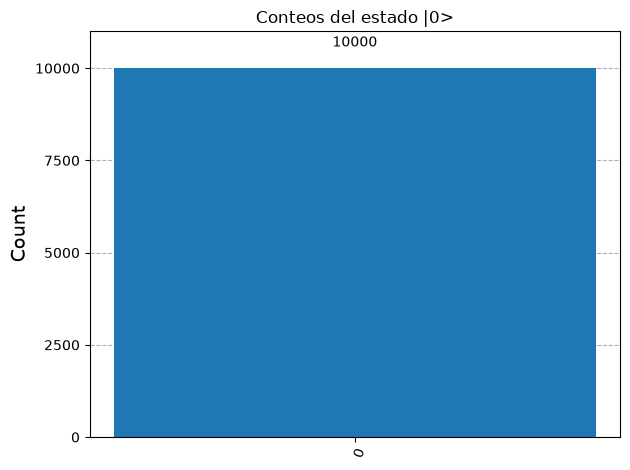

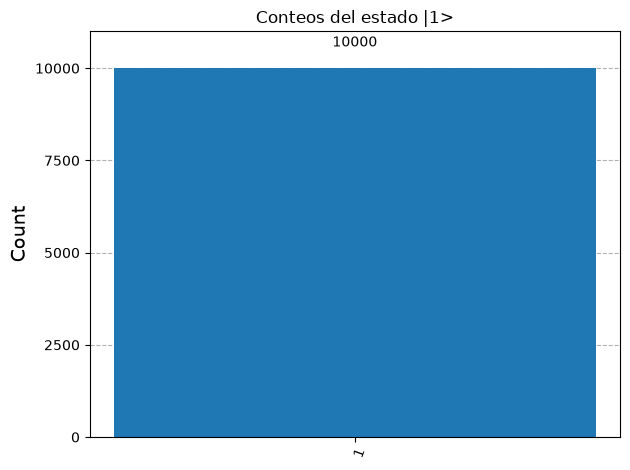

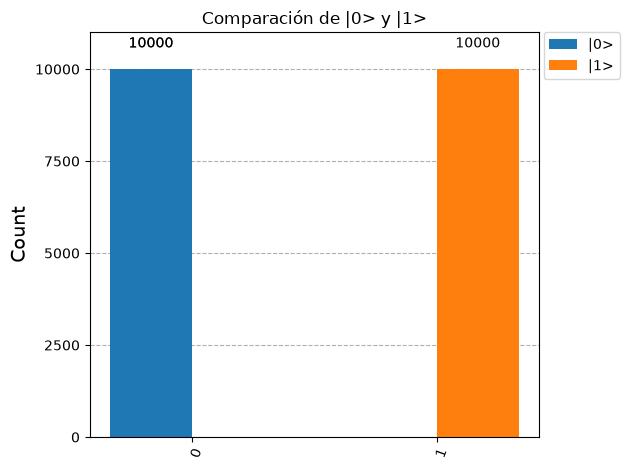

In [52]:
# Circuito |0>
circuito_0 = QuantumCircuit(1, 1)
circuito_0.measure(0, 0)

conteos_0 = ejecutar_con_shots(circuito_0, shots=1000)


# Circuito |1>
circuito_1 = QuantumCircuit(1, 1)
circuito_1.x(0)
circuito_1.measure(0, 0)

conteos_1 = ejecutar_con_shots(circuito_1, shots=1000)

# Histograma de |0>
fig0 = plot_histogram(
    conteos_0,
    title="Conteos del estado |0>"
)
display(fig0)


# Histograma de |1>
fig1 = plot_histogram(
    conteos_1,
    title="Conteos del estado |1>"
)
display(fig1)


# Histograma conjunto
fig2 = plot_histogram(
    [conteos_0, conteos_1],
    legend=["|0>", "|1>"],
    title="Comparación de |0> y |1>"
)
display(fig2)

### Responde

1. ¿Qué información representa el histograma?
2. ¿Muestra el circuito o el vector de estado?
3. ¿Muestra amplitudes o fases?

**Respuesta:** 
1. Representa cuántas veces aparece cada resultado de la medida.
2. No muestra directamente el circuito ni el vector de estado.
3. No muestra amplitudes complejas ni fases, solamente conteos

# Parte G. Simulación exacta y muestreo

## Ejercicio 20. Primera superposición

Crea un circuito con una puerta $H$, obtén su vector y compáralo con $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$. Muestra probabilidades exactas.

In [53]:
circuito_plus = QuantumCircuit(1)
circuito_plus.h(0)

# TODO: aplica H

estado_plus = Statevector.from_instruction(circuito_plus)
ket_plus_numpy = np.array([1 / np.sqrt(2), 1 / np.sqrt(2)], dtype=complex)


amplitudes_h = estado_plus.data
amplitudes_plus = ket_plus_numpy

prob_h = np.abs(amplitudes_h) ** 2
prob_plus = np.abs(amplitudes_plus) ** 2


# TODO: muestra y compara amplitudes y probabilidades

print(f"Con H: {amplitudes_h} P(0) ={prob_h[0]:.2f}, P(1) = {prob_h[1]:.2f}; |+>: {amplitudes_plus} P(0)= {prob_plus[0]:.2f}, P(1) = {prob_plus[1]:.2f}")


Con H: [0.70711+0.j 0.70711+0.j] P(0) =0.50, P(1) = 0.50; |+>: [0.70711+0.j 0.70711+0.j] P(0)= 0.50, P(1) = 0.50


## Ejercicio 21. Medida de la superposición

Crea una copia, añade medidas y ejecútala con 10, 100, 1.000 y 10.000 shots. Calcula $f(0)$, $f(1)$ y $|f(0)-1/2|$.

In [54]:
circuito_plus_medida = circuito_plus.copy()
circuito_plus_medida.measure_all()

# TODO: añade medidas

shots_superposicion = [10, 100, 1_000, 10_000]
resultados_superposicion = []

# TODO: ejecuta y almacena shots, conteos, frecuencias y error

simulador = AerSimulator()
circuito_plus_medida_transpilado = transpile(circuito_plus_medida, simulador)

for shot in shots_superposicion:
    resultado=simulador.run(circuito_plus_medida_transpilado, shots= shot, seed_simulator= 42).result()

    conteos = resultado.get_counts()
    f0 = conteos.get("0", 0) / shot
    f1 = conteos.get("1", 0) / shot
    error = abs(f0 - 1/2)

    resultados_superposicion.append({
        "shots": shot,
        "conteos": conteos,
        "f(0)": f0,
        "f(1)": f1,
        "error": error
    })

    print(
        f"Shots = {shot:5d} | "
        f"conteos = {conteos} | "
        f"f(0) = {f0:.4f} | "
        f"f(1) = {f1:.4f} | "
        f"|f(0)-1/2| = {error:.4f}"
    )

Shots =    10 | conteos = {'0': 5, '1': 5} | f(0) = 0.5000 | f(1) = 0.5000 | |f(0)-1/2| = 0.0000
Shots =   100 | conteos = {'0': 49, '1': 51} | f(0) = 0.4900 | f(1) = 0.5100 | |f(0)-1/2| = 0.0100
Shots =  1000 | conteos = {'0': 514, '1': 486} | f(0) = 0.5140 | f(1) = 0.4860 | |f(0)-1/2| = 0.0140
Shots = 10000 | conteos = {'1': 5079, '0': 4921} | f(0) = 0.4921 | f(1) = 0.5079 | |f(0)-1/2| = 0.0079


### Responde

1. ¿Coinciden exactamente frecuencias y probabilidades?
2. ¿Qué sucede normalmente al aumentar los shots?
3. ¿Debe disminuir estrictamente el error en cada fila?
4. ¿Qué diferencia hay respecto a $|0\rangle$ y $|1\rangle$?
5. ¿Se conserva la fase en los conteos?

**Respuesta:** 

1. No tienen por qué coincidir exactamente debido a la aleatoriedad de las medidas.
2. Normalmente las frecuencias se aproximan a las probabilidades teóricas.
3. No, el error puede aumentar puntualmente aunque la tendencia general sea disminuir.
4. Los estados \(|0\rangle\) y \(|1\rangle\) tienen resultados deterministas, mientras que \(|+\rangle\) puede producir 0 o 1.
5. No, los conteos no conservan la información de fase.

## Ejercicio 22. Gráfica de convergencia

Representa shots frente a frecuencia de 0, con eje horizontal logarítmico y una línea teórica en 0,5. Interpreta la gráfica.

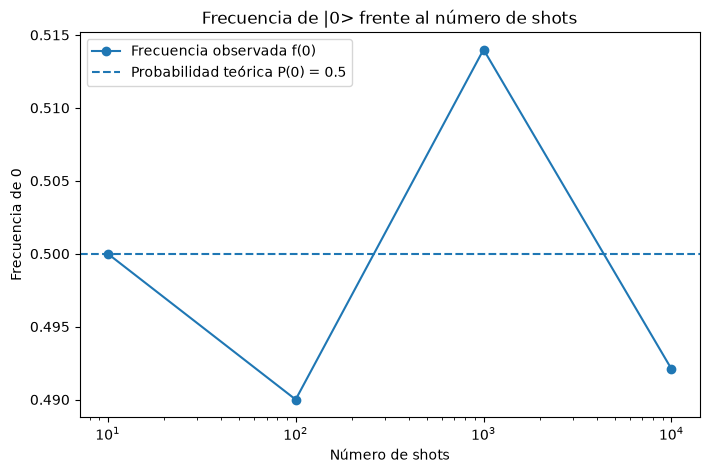

In [55]:
# TODO: extrae los datos y crea la gráfica completa

shots = [resultado["shots"] for resultado in resultados_superposicion]
frecuencias_0 = [resultado["f(0)"] for resultado in resultados_superposicion]

# Crear gráfica
plt.figure(figsize=(8, 5))

plt.plot(
    shots,
    frecuencias_0,
    marker="o",
    label="Frecuencia observada f(0)"
)

# Línea teórica P(0) = 0.5
plt.axhline(
    y=0.5,
    linestyle="--",
    label="Probabilidad teórica P(0) = 0.5"
)

# Eje horizontal logarítmico
plt.xscale("log")

plt.xlabel("Número de shots")
plt.ylabel("Frecuencia de 0")
plt.title("Frecuencia de |0> frente al número de shots")
plt.legend()

plt.show()

**Interpretación:** 

La frecuencia observada de obtener 0 oscila alrededor de 0,5. Al aumentar los shots, normalmente se aproxima a la probabilidad teórica, aunque el error no disminuye siempre de forma continua. Con 10.000 shots, la frecuencia obtenida en el cuaderno es 0,4921, bastante cercana al valor esperado de 0,5

## Ejercicio 23. Comparación exacta y experimental

Con 10.000 shots, construye una tabla con resultado, amplitud, probabilidad exacta, conteo y frecuencia.

In [56]:
# TODO: construye y muestra la tabla comparativa


# Buscar el resultado de 10.000 shots
resultado_10000 = next(
    r for r in resultados_superposicion
    if r["shots"] == 10_000
)

conteos_10000 = resultado_10000["conteos"]


amplitud_0 = estado_plus.data[0]
amplitud_1 = estado_plus.data[1]
prob_0 = abs(amplitud_0) ** 2
prob_1 = abs(amplitud_1) ** 2
conteo_0 = conteos_10000.get("0", 0)
conteo_1 = conteos_10000.get("1", 0)
frecuencia_0 = conteo_0 / 10_000
frecuencia_1 = conteo_1 / 10_000


print(
    f"{'Resultado':<12}"
    f"{'Amplitud':<22}"
    f"{'Prob. exacta':<18}"
    f"{'Conteo':<12}"
    f"{'Frecuencia':<12}"
)

print("-" * 76)

print(
    f"{'0':<12}"
    f"{str(round(amplitud_0.real, 4)):<22}"
    f"{prob_0:<18.4f}"
    f"{conteo_0:<12}"
    f"{frecuencia_0:<12.4f}"
)

print(
    f"{'1':<12}"
    f"{str(round(amplitud_1.real, 4)):<22}"
    f"{prob_1:<18.4f}"
    f"{conteo_1:<12}"
    f"{frecuencia_1:<12.4f}"
)

Resultado   Amplitud              Prob. exacta      Conteo      Frecuencia  
----------------------------------------------------------------------------
0           0.7071                0.5000            4921        0.4921      
1           0.7071                0.5000            5079        0.5079      


### Responde

1. ¿Qué columnas proceden de `Statevector`?
2. ¿Cuáles requieren medida?
3. ¿Cuál conserva información de fase?
4. ¿Por qué los conteos no reconstruyen el estado completo?

**Respuesta:**
1. Las amplitudes y las probabilidades exactas proceden de Statevector.
2. Los conteos y las frecuencias experimentales requieren medidas.
3. Las amplitudes complejas del vector de estado conservan la información de fase.
4. Porque los conteos solamente muestran resultados observados, no las fases relativas del estado

# Parte H. Circuitos de dos qubits

## Ejercicio 24. Estado inicial

Crea dos qubits, obtén el vector y el diccionario de probabilidades, y comprueba que representan $|00\rangle$.

|00>
[]
[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
P(|00>) = 1.0


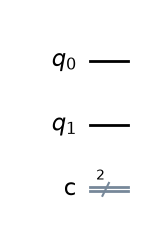

|01>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=())]
[0.+0.j 1.+0.j 0.+0.j 0.+0.j]
P(|01>) = 1.0


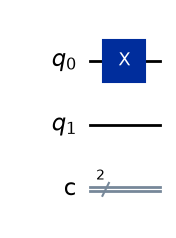

|10>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=())]
[0.+0.j 0.+0.j 1.+0.j 0.+0.j]
P(|10>) = 1.0


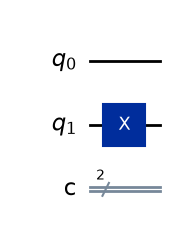

|11>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=())]
[0.+0.j 0.+0.j 0.+0.j 1.+0.j]
P(|11>) = 1.0


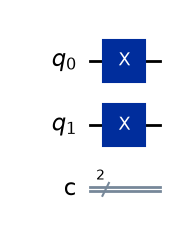

In [57]:
circuito_00 = QuantumCircuit(2,2)
circuito_01 = QuantumCircuit(2,2)
circuito_01.x(0)
circuito_10 = QuantumCircuit(2,2)
circuito_10.x(1)
circuito_11 = QuantumCircuit(2,2)
circuito_11.x(0)
circuito_11.x(1)

circuitos = {
    "00": circuito_00,
    "01": circuito_01,
    "10": circuito_10,
    "11": circuito_11
} 


# TODO: muestra vector, dimensión y probabilidades

for k, circuito in circuitos.items():
    print(f"|{k}>")
    info = circuito.data
    print(info)
    estado = Statevector.from_instruction(circuito)
    amp = estado.data
    print(amp)
    prob = estado.probabilities_dict()
    for key, valor in prob.items():
        print(f"P(|{key}>) = {valor}")
    display(circuito.draw(output="mpl"))
    

### Responde

1. ¿Cuántas amplitudes contiene?
2. ¿Por qué son cuatro?
3. ¿Cuál es el orden de la base?
4. ¿Qué dimensión tendrá un estado de tres qubits?

**Respuesta:** 

1. Tiene cuatro amplitudes.
2. Porque dos qubits necesitan 2^2=4 estados de la base.
3. El orden es |00>, |01>, |10>, |11>.
4. Un estado de tres qubits tendrá 2^3=8 amplitudes

## Ejercicio 25. Base computacional de dos qubits
Construye circuitos para $|00\rangle$, $|01\rangle$, $|10\rangle$ y $|11\rangle$. Dibuja cada uno y muestra su vector y `probabilities_dict()`.

|00>
[]
[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
P(|00>) = 1.0


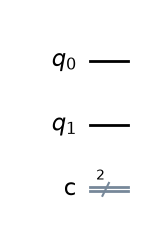

|01>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=())]
[0.+0.j 1.+0.j 0.+0.j 0.+0.j]
P(|01>) = 1.0


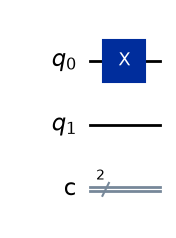

|10>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=())]
[0.+0.j 0.+0.j 1.+0.j 0.+0.j]
P(|10>) = 1.0


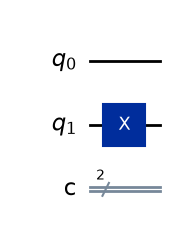

|11>
[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=1>,), clbits=())]
[0.+0.j 0.+0.j 0.+0.j 1.+0.j]
P(|11>) = 1.0


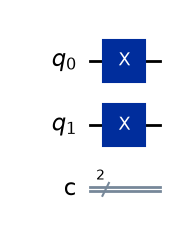

In [58]:
# TODO: construye los cuatro circuitos
circuito_00= QuantumCircuit(2,2)
circuito_01= QuantumCircuit(2,2)
circuito_01.x(0)
circuito_10= QuantumCircuit(2,2)
circuito_10.x(1)
circuito_11= QuantumCircuit(2,2)
circuito_11.x(0)
circuito_11.x(1)

circuitos_base_2q = {
    "|00>": circuito_00,
    "|01>": circuito_01,
    "|10>": circuito_10,
    "|11>": circuito_11
    # Completa el diccionario
}



for k, circuito in circuitos_base_2q.items():
    print(f"{k}")
    info = circuito.data
    print(info)
    estado = Statevector.from_instruction(circuito)
    amp = estado.data
    print(amp)
    prob = estado.probabilities_dict()
    for key, valor in prob.items():
        print(f"P(|{key}>) = {valor}")
    display(circuito.draw(output="mpl"))


# TODO: visualiza y analiza todos los circuitos

## Ejercicio 26. Orden de bits

Aplica `x(0)` a dos qubits. Muestra el vector y el diccionario de probabilidades.

In [59]:
circuito_orden = QuantumCircuit(2)
circuito_orden.x(0)
# TODO: aplica X a q_0 y analiza el estado

estado_orden = Statevector.from_instruction(circuito_orden)


print("Vector de estado:")
print(estado_orden.data)

print("Probabilidades:")
print(estado_orden.probabilities_dict())


Vector de estado:
[0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Probabilidades:
{np.str_('01'): np.float64(1.0)}


### Responde

1. ¿Por qué aparece `"01"` y no `"10"`?
2. ¿Qué valores tienen $q_0$ y $q_1$?
3. ¿En qué orden se muestran las cadenas?
4. ¿Cuál es el orden del vector de amplitudes?

**Respuesta:** 
1. Porque Qiskit utiliza el orden |q_1q_0>, colocando q0 a la derecha.
2. q_0=1 y q_1=0.
3. Las cadenas se muestran del bit más significativo al menos significativo.
4. El vector sigue el orden |00>, |01>, |10>, |11>.

## Ejercicio 27. Medida de dos qubits

Para los cuatro estados de la base, crea copias con dos bits clásicos, mide cada qubit en el bit del mismo índice y ejecuta 1.000 shots.

In [60]:
conteos_base_2q = {}

# TODO: añade medidas, ejecuta y almacena conteos para los cuatro estados

simulador = AerSimulator()

for nombre, circuito in circuitos_base_2q.items():

    circuito_medida = circuito.copy()
    circuito_medida.measure(0, 0)
    circuito_medida.measure(1, 1)
    circuito_transpilado = transpile(circuito_medida, simulador)

    resultado = simulador.run(
        circuito_transpilado,
        shots=1000,
        seed_simulator=42
    ).result()

    conteos = resultado.get_counts()
    conteos_base_2q[nombre] = conteos


# Mostrar resultados
for nombre, conteos in conteos_base_2q.items():
    print(f"{nombre}: {conteos}")

|00>: {'00': 1000}
|01>: {'01': 1000}
|10>: {'10': 1000}
|11>: {'11': 1000}


## Ejercicio 28. Intercambio de bits clásicos
Prepara $|01\rangle$ y compara la medida directa `q0→c0, q1→c1` con la medida intercambiada `q0→c1, q1→c0`.

In [61]:
# TODO: crea y ejecuta ambos circuitos
simulador = AerSimulator()


# Medida directa
circuito_directo = QuantumCircuit(2, 2)
circuito_directo.x(0)

circuito_directo.measure(0, 0)
circuito_directo.measure(1, 1)

resultado_directo = simulador.run(
    transpile(circuito_directo, simulador),
    shots=1000,
    seed_simulator=42
).result()

conteos_directo = resultado_directo.get_counts()


# Medida intercambiada
circuito_intercambiado = QuantumCircuit(2, 2)
circuito_intercambiado.x(0)

circuito_intercambiado.measure(0, 1)
circuito_intercambiado.measure(1, 0)

resultado_intercambiado = simulador.run(
    transpile(circuito_intercambiado, simulador),
    shots=1000,
    seed_simulator=42
).result()

conteos_intercambiado = resultado_intercambiado.get_counts()


print("Medida directa:", conteos_directo)
print("Medida intercambiada:", conteos_intercambiado)

Medida directa: {'01': 1000}
Medida intercambiada: {'10': 1000}


### Responde

1. ¿Cambia el estado anterior a la medida?
2. ¿Cambia la cadena clásica?
3. ¿Qué demuestra el experimento?
4. ¿Por qué debe revisarse el mapeo entre qubits y bits?

**Respuesta:** 

1. No, el estado cuántico antes de medir sigue siendo |01>.
2. Sí, la cadena cambia de "01" a "10".
3. Demuestra que el resultado clásico depende de la correspondencia entre qubits y bits clásicos.
4. Para interpretar correctamente los resultados y no confundir qué qubit produjo cada valor.

# Parte I. Interpretación conceptual

## Ejercicio 29. Clasificación

Clasifica y justifica: `QuantumCircuit(2,2)`, `Statevector.from_instruction(c)`, `estado.data`, `estado.probabilities()`, `measure()`, `"01"`, `{"00":492,"11":508}`, `492/1000`, `plot_histogram()` y `simulador.run()`.

**Respuesta:** 

1. QuantumCircuit(2,2)->	Construcción de un circuito con 2 qubits y 2 bits clásicos.
2. Statevector.from_instruction(c)->	Simulación exacta para obtener el estado cuántico.
3. estado.data->	Array de amplitudes complejas del estado.
4. estado.probabilities()->	Probabilidades teóricas de medida.
5. measure()->	Operación de medida cuántica.
6. "01"->	Cadena clásica que representa un resultado.
7. {"00":492,"11":508}->	Diccionario de conteos experimentales.
8. 492/1000->	Frecuencia relativa, igual a 0,492.
9. plot_histogram()->	Visualización gráfica de los conteos.
10. simulador.run()->	Ejecución del circuito en el simulador.

## Ejercicio 30. Verdadero o falso

Justifica:

1. Crear un circuito lo ejecuta inmediatamente.
2. Los qubits comienzan por defecto en $|0\rangle$.
3. Un bit clásico puede contener una superposición.
4. Declarar bits clásicos añade medidas.
5. `Statevector.data` contiene amplitudes.
6. `probabilities_dict()` devuelve conteos.
7. Cada shot incluye una nueva preparación.
8. El histograma muestra amplitudes.
9. La transpilación adapta el circuito al backend.
10. Dos circuitos distintos pueden producir el mismo estado final.
11. Probabilidades iguales implican amplitudes iguales.
12. Qiskit muestra $q_0$ a la izquierda de las cadenas.
13. `x(0)` sobre dos qubits prepara $|01\rangle$.
14. Un simulador ideal incluye ruido automáticamente.
15. La medida puede eliminar información de fase.

**Respuesta:** 

1. Falso	Crear un circuito solo define sus operaciones.
2. Verdadero	Los qubits comienzan por defecto en \(|0\rangle\).
3. Falso	Un bit clásico solo almacena 0 o 1.
4. Falso	Los bits clásicos no realizan medidas automáticamente.
5. Verdadero	.data contiene las amplitudes complejas.
6. Falso	Devuelve probabilidades, no conteos.
7. Verdadero	Cada shot corresponde a una nueva ejecución con el estado preparado.
8. Falso	El histograma muestra conteos, no amplitudes.
9. Verdadero	Adapta las instrucciones al backend.
10. Verdadero	Diferentes secuencias pueden producir el mismo estado final.
11. Falso	Las amplitudes pueden tener fases distintas.
12. Falso	q0 aparece a la derecha en las cadenas de bits de Qiskit.
13. Verdadero	x(0) sobre dos qubits prepara \(|01\rangle\).
14. Falso	Un simulador ideal no añade ruido automáticamente.
15. Verdadero	La medida no conserva toda la información de fase del estado.

# Reto avanzado. Analizador de circuitos

Implementa una función que reciba un circuito sin medidas y devuelva el vector, probabilidades exactas, una copia con medidas, conteos y frecuencias. Debe validar el tipo, los shots y que el circuito no contenga medidas.

In [62]:
def analizar_circuito(circuito_sin_medidas, shots=1000, semilla=42):
    """Analiza exactamente un circuito y simula después sus medidas."""

    if not isinstance(circuito_sin_medidas, QuantumCircuit):
        raise TypeError("Debe ser un QuantumCircuit.")

    if not isinstance(shots, int) or isinstance(shots, bool) or shots <= 0:
        raise ValueError("shots debe ser un entero positivo.")

    if circuito_sin_medidas.count_ops().get("measure", 0) > 0:
        raise ValueError("El circuito no debe contener medidas.")

    # Estado y probabilidades exactas
    estado = Statevector.from_instruction(circuito_sin_medidas)
    vector = estado.data.copy()
    probabilidades = estado.probabilities_dict()

    # Copia para añadir las medidas
    circuito_medido = circuito_sin_medidas.copy()
    circuito_medido.measure_all()

    # Simulación
    simulador = AerSimulator()
    circuito_t = transpile(circuito_medido, simulador)

    resultado = simulador.run(
        circuito_t,
        shots=shots,
        seed_simulator=semilla
    ).result()

    conteos = resultado.get_counts()

    # Frecuencias experimentales
    frecuencias = {
        resultado: cantidad / shots
        for resultado, cantidad in conteos.items()
    }

    return {
        "vector": vector,
        "probabilidades": probabilidades,
        "circuito_medido": circuito_medido,
        "conteos": conteos,
        "frecuencias": frecuencias
    }


pruebas = {}

pruebas["Vacio"] = QuantumCircuit(1)

pruebas["X"] = QuantumCircuit(1)
pruebas["X"].x(0)

pruebas["XX"] = QuantumCircuit(1)
pruebas["XX"].x(0)
pruebas["XX"].x(0)

pruebas["H"] = QuantumCircuit(1)
pruebas["H"].h(0)

pruebas["01"] = QuantumCircuit(2)
pruebas["01"].x(0)

for nombre, circuito in pruebas.items():
    resultado = analizar_circuito(circuito)

    print("\nCircuito:", nombre)
    print("Vector:", resultado["vector"])
    print("Probabilidades:", resultado["probabilidades"])
    print("Conteos:", resultado["conteos"])
    print("Frecuencias:", resultado["frecuencias"])


Circuito: Vacio
Vector: [1.+0.j 0.+0.j]
Probabilidades: {np.str_('0'): np.float64(1.0)}
Conteos: {'0': 1000}
Frecuencias: {'0': 1.0}

Circuito: X
Vector: [0.+0.j 1.+0.j]
Probabilidades: {np.str_('1'): np.float64(1.0)}
Conteos: {'1': 1000}
Frecuencias: {'1': 1.0}

Circuito: XX
Vector: [1.+0.j 0.+0.j]
Probabilidades: {np.str_('0'): np.float64(1.0)}
Conteos: {'0': 1000}
Frecuencias: {'0': 1.0}

Circuito: H
Vector: [0.70711+0.j 0.70711+0.j]
Probabilidades: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Conteos: {'0': 514, '1': 486}
Frecuencias: {'0': 0.514, '1': 0.486}

Circuito: 01
Vector: [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Probabilidades: {np.str_('01'): np.float64(1.0)}
Conteos: {'01': 1000}
Frecuencias: {'01': 1.0}


### Responde

1. ¿Qué parte es exacta?
2. ¿Qué parte depende de los shots?
3. ¿Qué información desaparece en los conteos?
4. ¿Por qué se conserva el circuito original sin medidas?
5. ¿Cómo comprobarías la coherencia entre conteos y shots?

**Respuesta:** 

1. El vector de estado y las probabilidades calculadas con Statevector son exactos dentro de la precisión numérica.
2. Los conteos y las frecuencias experimentales dependen del número de shots.
3. Desaparece la información sobre las fases de las amplitudes.
4. Para conservar las operaciones originales y poder calcular su estado sin medidas.
5. Comprobando que la suma de todos los conteos coincide con el número de shots.

# Pruebas mínimas

Descomenta estas pruebas al completar la práctica y añade casos inválidos.

In [69]:
# Pruebas básicas
assert circuito_0.num_qubits == 1
assert np.allclose(Statevector.from_instruction(pruebas["Vacio"]).data, [1, 0])
assert np.allclose(Statevector.from_instruction(pruebas["X"]).data, [0, 1])
assert np.allclose(Statevector.from_instruction(pruebas["XX"]).data, [1, 0])
assert np.allclose(X_numpy @ ket_0_numpy, [0, 1])
conteos_prueba = analizar_circuito(pruebas["Vacio"], shots=1000)["conteos"]

assert sum(conteos_prueba.values()) == 1000
assert conteos_prueba.get("0", 0) == 1000
assert np.allclose(estado_plus.probabilities(), [0.5, 0.5])
assert np.allclose(estado_plus.probabilities(), [0.5, 0.5])

# Frecuencias
assert calcular_frecuencias({"0": 250, "1": 750}) == {"0": 0.25, "1": 0.75}

# Dos qubits
resultado = analizar_circuito(pruebas["01"])
assert np.allclose(resultado["vector"], [0, 1, 0, 0])
assert resultado["conteos"] == {"01": 1000}

# Shots inválidos
for shots in [0, -1, 1.5, True]:
    try:
        analizar_circuito(QuantumCircuit(1), shots=shots)
    except ValueError:
        pass
    else:
        raise AssertionError("Shots inválidos aceptados")

# Conteos inválidos (la función actual lanza ZeroDivisionError)
try:
    calcular_frecuencias({})
except ZeroDivisionError:
    pass
else:
    raise AssertionError("Conteos vacíos aceptados")

# Conservación del circuito original
qc = QuantumCircuit(1)
qc.h(0)
copia = qc.copy()

analizar_circuito(qc)

assert qc == copia
assert qc.count_ops().get("measure", 0) == 0

print("Pruebas superadas")

Pruebas superadas
